# Validação fora do tempo: o modelo do ENEM 2023 testado no ENEM 2025

**Pergunta:** as relações entre perfil socioeconômico e nota que o modelo aprendeu com o ENEM 2023 continuam valendo
dois anos depois?

Para responder, usamos o modelo de 2023 **sem nenhum ajuste** para prever a nota média de cada estado (UF) no ENEM
2025, gravamos essa previsão no GitHub e só depois abrimos as notas reais de 2025. Este notebook mostra cada etapa e
os resultados.

Ele lê só arquivos que estão no repositório (os dados brutos do INEP têm vários GB e ficam fora do Git). Os números
vêm dos scripts `congelar_modelo.py`, `baixar_ano.py`, `calibrar_universo.py`, `prever_2025.py` e `realidade_2025.py`;
a comparação é refeita aqui e conferida com o arquivo gravado. O plano completo está em `PLANO_PREVISAO_2026.md`.

In [1]:
import json
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from realidade_2025 import comparar
from src.estilo import AZUL, LARANJA, TINTA_SECUNDARIA, aplicar_estilo

aplicar_estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")


def ler(caminho):
    return json.loads(Path(caminho).read_text(encoding="utf-8"))


def br(v, casas=1):
    """Número no padrão brasileiro (1.234,5), com o sinal de menos tipográfico."""
    return f"{v:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".").replace("-", "−")


def sinal(v, casas=1):
    return ("+" if v > 0 else "−" if v < 0 else "") + br(abs(v), casas)


modelos = ler("resultados/modelos/modelos.json")
meta25 = ler("dados/processados/enem2025_participantes_meta.json")
calib = ler("resultados/calibracao_universo_2023.json")
prev = ler("resultados/previsao_2025.json")
val = ler("resultados/validacao_2025.json")
real_uf = pd.read_csv("dados/processados/enem2025_resultados_uf.csv", index_col="UF")
real_esc = pd.read_csv("dados/processados/enem2025_resultados_uf_escola.csv", index_col=["UF", "ESCOLA"])
regiao = pd.read_csv("dados/ibge_uf.csv").set_index("UF")["REGIAO"]
print(f"Arquivos carregados: previsão de {prev['gerado_em'][:10]}, {len(real_uf)} UFs na realidade de 2025.")

Arquivos carregados: previsão de 2026-11-10, 27 UFs na realidade de 2025.


## 1. A ideia: expectativa × realidade

O modelo só viu um ano (2023), então ele não aprende tendência. O que se testa é se as relações que ele aprendeu
(escola, renda, escolaridade dos pais, internet, região...) ainda explicam as diferenças entre os estados em 2025.

Comparamos três previsões da nota final média de cada UF em 2025:

| Previsão | Como é feita | Para que serve |
|---|---|---|
| **A. Repetição** | a média real de cada UF em 2023 | régua mínima: o modelo precisa ser melhor que "repetir o ano anterior" |
| **B. Modelo + perfil de 2023** | o modelo aplicado aos alunos de 2023 | o que se esperaria se nada tivesse mudado |
| **C. Modelo + perfil de 2025** | o modelo aplicado aos alunos de 2025 | se as relações de 2023 ainda valem com o público novo |

A diferença entre B e C mostra quanto pesa a **mudança no perfil** dos inscritos. O erro que sobra em C é o que o
modelo não enxerga: mudanças na prova, na correção, em políticas locais ou nas próprias relações.

## 2. Passo 1: congelar o modelo de 2023

Antes de olhar para 2025, o modelo da Entrega 2 foi retreinado e conferido: ele tem de reproduzir exatamente as
métricas do notebook. Depois foi salvo em `resultados/modelos/` com uma "impressão digital" (SHA-256), que é conferida
toda vez que ele é carregado. Assim dá para provar que nada foi reajustado depois de ver os dados novos.

Junto foi salvo um segundo modelo, o de **presença**: ele estima a chance de cada inscrito fazer as cinco provas.
Ele é necessário porque, a partir de 2024, o INEP separa o questionário (arquivo PARTICIPANTES) das notas e da
presença (arquivo RESULTADOS), sem uma chave que ligue os dois.

In [2]:
reg, pres = modelos["regressao"], modelos["presenca"]
uf23 = reg["teste_por_uf"]
correcao = pres["teste_correcao_por_uf"]
display(Markdown(
    f"- Congelado em {modelos['congelado_em'][:10]} (scikit-learn {modelos['versoes']['scikit-learn']}, SEED = {modelos['SEED']}).\n"
    f"- Regressão no teste de 2023: R² = {br(reg['metricas']['teste']['R²'], 3)}, erro médio de "
    f"{br(reg['metricas']['teste']['MAE'])} pontos **por aluno**.\n"
    f"- Por UF, no teste de 2023, a média prevista errou {br(uf23['MAE'])} pontos em média "
    f"(correlação de posições = {br(uf23['spearman'], 2)}). É o tamanho de erro esperado se nada mudar.\n"
    f"- Presença: ROC-AUC = {br(pres['teste']['ROC-AUC'], 2)}; ponderar pela chance de presença reduziu o erro da "
    f"média por UF de {br(correcao['MAE_sem_correcao'])} para {br(correcao['MAE_ponderada_pela_presenca'])} pontos."))
pd.DataFrame({k: {"arquivo": v["arquivo"], "SHA-256 (início)": v["sha256"][:16]} for k, v in
              (("regressão", reg), ("presença", pres))}).T

- Congelado em 2026-11-10 (scikit-learn 1.9.1, SEED = 42).
- Regressão no teste de 2023: R² = 0,299, erro médio de 62,7 pontos **por aluno**.
- Por UF, no teste de 2023, a média prevista errou 9,3 pontos em média (correlação de posições = 0,85). É o tamanho de erro esperado se nada mudar.
- Presença: ROC-AUC = 0,71; ponderar pela chance de presença reduziu o erro da média por UF de 7,9 para 1,8 pontos.

,arquivo,SHA-256 (início)
regressão,regressao_nota_final.joblib,335291c19cbf0f3a
presença,presenca.joblib,8a38672df7e9b40c


## 3. Passo 2: o que mudou nos dados de 2025

Antes de baixar os microdados, comparamos os dicionários de 2023 e 2025 variável a variável
(`docs/equivalencia_2023_2025.md`). As mudanças que importam:

- **Renda familiar:** era a pergunta Q006 e virou a **Q007**. As faixas são as mesmas em salários mínimos, então a
  renda continua comparável. Em 2025 a Q006 é outra pergunta ("Você possui renda?"); o código para se as letras não
  forem as esperadas.
- **Computadores em casa:** Q024 virou Q021, com os mesmos códigos.
- **Internet:** em 2025 a pergunta é só sobre **wi-fi** (Q020), um conceito mais estreito que o de 2023.
- **Tipo de escola:** a variável de 2023 deixou de existir. Na previsão usamos a nova pergunta Q023 (trajetória
  declarada pelo aluno); quem estudou "parte na pública, parte na privada" entra como **pública** no cenário principal.
- **Sem ligação aluno a aluno:** a comparação é feita por **médias de UF**.

## 4. Passo 3: quem entra na comparação (o universo)

Em 2023 o universo foi: concluintes do ensino médio no ano, não treineiros, com escola informada. Em 2025, o arquivo
de notas (RESULTADOS) não diz quem é concluinte. Usamos uma aproximação: **alunos com a escola de conclusão
preenchida**. Para saber se ela é boa, fizemos duas checagens:

1. **Contagem por UF** (só contagens, nenhuma nota): o universo de PARTICIPANTES contra o universo aproximado de
   RESULTADOS. Critério combinado: diferença de até 5% em cada UF.
2. **Calibração com 2023**, que tem as duas informações no mesmo arquivo: quanto muda a nota média de cada UF ao
   trocar o universo verdadeiro pelo aproximado.

In [3]:
conf = meta25["conferencia_universo"]
cont = pd.DataFrame(conf["por_uf"]).T[["participantes", "resultados", "diferenca", "mista_pct"]].astype(float)
dif_total = cont["resultados"].sum() / cont["participantes"].sum() - 1
est = calib["estimativa_2025"]
display(Markdown(
    f"- **Contagem:** o universo aproximado tem {sinal(dif_total * 100)}% de inscritos no total; "
    f"{len(conf['ufs_acima_do_limite'])} UFs passam de 5% ({', '.join(conf['ufs_acima_do_limite'])}). "
    "Pelo critério, a aproximação não foi aceita sem mais testes.\n"
    f"- **Calibração com 2023:** lá a escola de conclusão estava preenchida para só {br(calib['cobertura_2023'] * 100)}% "
    f"dos concluintes, e a troca de universo mudou a média das UFs em {br(calib['MAE'])} pontos em média. Em 2025 falta "
    f"muito menos gente; supondo a mesma diferença de nota de 2023, o viés estimado para 2025 é de {br(est['MAE'])} "
    f"ponto em média (maior em {est['maior']['UF']}: {sinal(est['maior']['pontos'])}).\n"
    "- **Decisão:** comparação principal com as 27 UFs; duas sensibilidades: sem as UFs acima de 5% e com a realidade "
    "descontada do viés estimado.\n"
    f"- **Trajetória mista** (parte pública, parte privada): {br(conf['mista_total_pct'] * 100)}% dos inscritos.\n"
    f"- **O público cresceu:** {br(calib['universo_2023'], 0)} concluintes em 2023 e {br(calib['universo_2025'], 0)} em 2025 "
    f"({sinal(calib['crescimento_universo'] * 100)}%). Uma explicação possível é o Pé-de-Meia, que paga um bônus a alunos "
    "da rede pública que fazem os dois dias do ENEM (ver o documento de equivalência)."))
cont.rename(columns={"participantes": "inscritos PARTICIPANTES", "resultados": "inscritos RESULTADOS (aprox.)",
                     "diferenca": "diferença", "mista_pct": "trajetória mista"}).style.format(
    {"inscritos PARTICIPANTES": "{:,.0f}", "inscritos RESULTADOS (aprox.)": "{:,.0f}", "diferença": "{:+.1%}",
     "trajetória mista": "{:.1%}"})

- **Contagem:** o universo aproximado tem −4,0% de inscritos no total; 11 UFs passam de 5% (AL, DF, GO, MA, MS, MT, PA, PI, PR, RJ, RR). Pelo critério, a aproximação não foi aceita sem mais testes.
- **Calibração com 2023:** lá a escola de conclusão estava preenchida para só 68,4% dos concluintes, e a troca de universo mudou a média das UFs em 11,0 pontos em média. Em 2025 falta muito menos gente; supondo a mesma diferença de nota de 2023, o viés estimado para 2025 é de 1,4 ponto em média (maior em AL: +3,0).
- **Decisão:** comparação principal com as 27 UFs; duas sensibilidades: sem as UFs acima de 5% e com a realidade descontada do viés estimado.
- **Trajetória mista** (parte pública, parte privada): 4,8% dos inscritos.
- **O público cresceu:** 1.401.159 concluintes em 2023 e 1.810.641 em 2025 (+29,2%). Uma explicação possível é o Pé-de-Meia, que paga um bônus a alunos da rede pública que fazem os dois dias do ENEM (ver o documento de equivalência).

,inscritos PARTICIPANTES,inscritos RESULTADOS (aprox.),diferença,trajetória mista
AC,"10,057","9,642",-4.1%,2.4%
AL,"36,532","32,527",-11.0%,4.2%
AM,"49,994","48,966",-2.1%,2.7%
AP,"9,064","8,665",-4.4%,3.3%
BA,"138,622","133,968",-3.4%,5.0%
CE,"118,490","114,807",-3.1%,3.1%
DF,"27,048","25,473",-5.8%,5.9%
ES,"33,798","32,791",-3.0%,3.7%
GO,"72,648","67,427",-7.2%,5.9%
MA,"69,791","65,792",-5.7%,3.4%


## 5. Passo 4: a previsão cega

A regra mais importante: **a previsão foi gravada e enviada ao GitHub antes de qualquer nota de 2025 ser lida.**
Do arquivo de notas, até ali, só foram lidas a UF, a rede da escola e a presença (usada no cenário de sensibilidade
"presença calibrada"). O histórico do Git registra a ordem:

In [4]:
def historico(arquivo):
    """Commits que tocaram o arquivo (data e mensagem), do mais antigo para o mais novo."""
    try:
        saida = subprocess.run(["git", "log", "--reverse", "--format=%h  %ad  %s", "--date=format:%d/%m/%Y %H:%M",
                                "--", arquivo], capture_output=True, text=True, encoding="utf-8",
                               check=True).stdout.strip()
        return saida or "(sem commits)"
    except (OSError, subprocess.CalledProcessError):
        return "(histórico do Git indisponível nesta cópia)"


for rotulo, arquivo in [("Modelos congelados", "resultados/modelos/modelos.json"),
                        ("Amostra de 2025 (perfil)", "dados/processados/enem2025_participantes.parquet"),
                        ("Previsão cega", "resultados/previsao_2025.json"),
                        ("Notas reais de 2025", "dados/processados/enem2025_resultados_uf.csv")]:
    print(f"{rotulo}:\n  {historico(arquivo)}")

Modelos congelados:
  5c07845  10/11/2026 22:40  Congela os modelos de 2023 e mostra previsto x real por UF no teste
Amostra de 2025 (perfil):
  f452506  10/11/2026 23:16  Amostra de PARTICIPANTES 2025 (4% por UF, SEED 42), antes da previsão


Previsão cega:
  3eee3c2  10/11/2026 23:19  Previsão cega do ENEM 2025 (A, B, C e sensibilidades), antes das notas
Notas reais de 2025:
  d680dee  10/11/2026 23:25  Realidade do ENEM 2025 e comparação com a previsão cega


In [5]:
p = pd.DataFrame(prev["por_uf"]).T
tab_prev = p[["A", "B", "C"]].astype(float).join(regiao).rename(columns={"REGIAO": "região"})
display(Markdown(f"Previsão nacional: A = {br(prev['nacional']['A'])}, B = {br(prev['nacional']['B'])}, "
                 f"C = {br(prev['nacional']['C'])} pontos."))
tab_prev

Previsão nacional: A = 536,9, B = 536,2, C = 532,5 pontos.

,A,B,C,região
AC,510.12,513.11,506.32,Norte
AL,512.05,514.28,514.92,Nordeste
AM,491.42,502.46,496.26,Norte
AP,508.69,504.40,505.11,Norte
BA,526.99,524.07,513.47,Nordeste
CE,505.34,505.18,507.22,Nordeste
DF,554.26,546.50,552.05,Centro-Oeste
ES,554.51,546.97,546.20,Sudeste
GO,534.93,530.13,531.44,Centro-Oeste
MA,497.35,512.50,508.80,Nordeste


## 6. Passo 5: a realidade de 2025

Só depois do envio da previsão, as notas de 2025 foram lidas, no mesmo universo aproximado e só com quem fez as
cinco provas. A nota final é a média das cinco provas, como em 2023.

In [6]:
nac_real = val["nacional"]["real"]
display(Markdown(f"Média real nacional em 2025: **{br(nac_real)} pontos**, com {br(val['alunos_real'], 0)} alunos "
                 f"({sinal(nac_real - prev['nacional']['A'])} em relação a 2023)."))
real_uf[["n", "NOTA_FINAL"]].rename(columns={"n": "alunos", "NOTA_FINAL": "nota final real"})

Média real nacional em 2025: **524,1 pontos**, com 1.288.485 alunos (−12,8 em relação a 2023).

,alunos,nota final real
UF,,
AC,6739,499.21
AL,26450,483.42
AM,28793,474.90
AP,6888,496.76
BA,97228,500.01
CE,96263,499.33
DF,21291,550.42
ES,24506,541.29
GO,46218,530.10


## 7. Passo 6: a comparação

Para cada previsão calculamos, sobre as 27 UFs:

- **MAE** (erro médio absoluto): em média, quantos pontos a previsão errou, para mais ou para menos;
- **RMSE**: parecido com o MAE, mas pesa mais os erros grandes;
- versões **ponderadas** pelo número de alunos de cada UF (estados grandes contam mais);
- **viés**: o erro médio com sinal (positivo = a previsão ficou acima da realidade);
- **Pearson** e **Spearman**: se a previsão acerta a ordem dos estados (1 = perfeita).

A tabela é recalculada aqui a partir dos arquivos e conferida com o resultado gravado em `resultados/validacao_2025.json`.

In [7]:
res = comparar(prev, real_uf, real_esc)
for var, tab in res["nota_final_por_uf"].items():  # mesma conta do arquivo gravado
    for cen, m in tab.items():
        assert all(abs(m[k] - val["nota_final_por_uf"][var][cen][k]) < 1e-6 for k in m), (var, cen)
principal = pd.DataFrame(res["nota_final_por_uf"]["principal"]).T.loc[["A", "B", "C"]]
principal[["MAE", "MAE_ponderado", "RMSE", "RMSE_ponderado", "vies", "vies_ponderado", "pearson", "spearman"]]

,MAE,MAE_ponderado,RMSE,RMSE_ponderado,vies,vies_ponderado,pearson,spearman
A,12.98,12.72,14.74,14.32,12.98,12.72,0.96,0.92
B,12.85,12.34,16.21,14.89,12.08,11.93,0.89,0.84
C,10.66,9.43,13.18,11.47,9.41,8.16,0.93,0.90


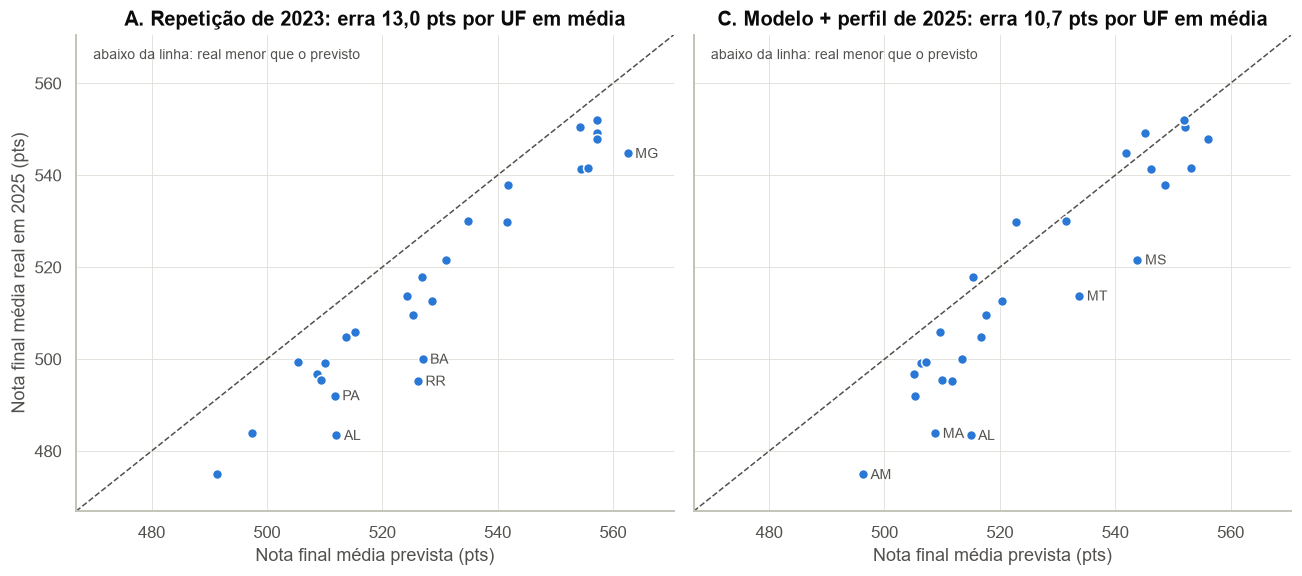

In [8]:
# Previsto × real por UF: régua A (repetição) e modelo C (perfil de 2025)
real = real_uf["NOTA_FINAL"]
fig, eixos = plt.subplots(1, 2, figsize=(12, 5.4), sharex=True, sharey=True)
lim = [min(real.min(), p[["A", "C"]].astype(float).min().min()) - 8, max(real.max(), p[["A", "C"]].astype(float).max().max()) + 8]
for ax, cen, titulo in [(eixos[0], "A", "A. Repetição de 2023"), (eixos[1], "C", "C. Modelo + perfil de 2025")]:
    prevista = p[cen].astype(float)
    ax.plot(lim, lim, ls="--", lw=1, color=TINTA_SECUNDARIA)
    ax.scatter(prevista, real, s=42, color=AZUL, edgecolor="white", linewidth=1, zorder=3)
    for u in (prevista - real).abs().nlargest(5).index:  # só os cinco maiores erros recebem rótulo
        ax.annotate(u, (prevista[u], real[u]), xytext=(5, -3), textcoords="offset points", fontsize=9, color=TINTA_SECUNDARIA)
    mae = res["nota_final_por_uf"]["principal"][cen]["MAE"]
    ax.set_title(f"{titulo}: erra {br(mae)} pts por UF em média")
    ax.set_xlabel("Nota final média prevista (pts)")
    ax.text(lim[0] + 3, lim[1] - 3, "abaixo da linha: real menor que o previsto", va="top", fontsize=9, color=TINTA_SECUNDARIA)
eixos[0].set_ylabel("Nota final média real em 2025 (pts)")
eixos[0].set_xlim(lim)
eixos[0].set_ylim(lim)
fig.tight_layout()
plt.show()

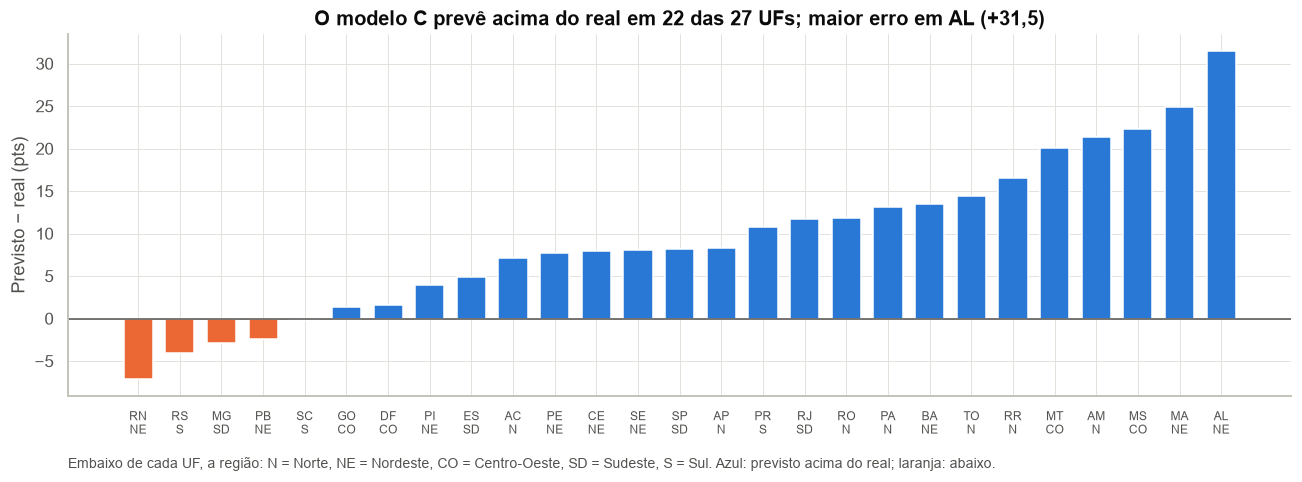

In [9]:
# Erro de C por UF (previsto − real), com a região na etiqueta
erros = pd.DataFrame(res["erros_por_uf"]).T
erro_c = erros["C"].astype(float).sort_values()
siglas = {"Norte": "N", "Nordeste": "NE", "Centro-Oeste": "CO", "Sudeste": "SD", "Sul": "S"}  # "SE" seria Sergipe
fig, ax = plt.subplots(figsize=(12, 4.6))
ax.bar([f"{u}\n{siglas[regiao[u]]}" for u in erro_c.index], erro_c, color=[AZUL if v > 0 else LARANJA for v in erro_c],
       width=0.7)
ax.axhline(0, color=TINTA_SECUNDARIA, lw=1)
ax.set_ylabel("Previsto − real (pts)")
ax.set_title(f"O modelo C prevê acima do real em {int((erro_c > 0).sum())} das 27 UFs; maior erro em {erro_c.idxmax()} "
             f"({sinal(erro_c.max())})")
ax.tick_params(axis="x", labelsize=8)
ax.text(0, -0.2, "Embaixo de cada UF, a região: N = Norte, NE = Nordeste, CO = Centro-Oeste, SD = Sudeste, S = Sul. "
        "Azul: previsto acima do real; laranja: abaixo.", transform=ax.transAxes, fontsize=9, color=TINTA_SECUNDARIA)
fig.tight_layout()
plt.show()

## 8. Quanto a mudança de perfil explica (B → C)

B usa o perfil dos alunos de 2023 e C, o de 2025; o modelo é o mesmo. Se C fica mais perto da realidade que B, a
diferença vem só de quem passou a fazer a prova.

In [10]:
perf = res["mudanca_de_perfil"]
nac = perf["nacional"]
display(Markdown(
    f"- Erro médio por UF: B = {br(perf['MAE_B'], 2)} e C = {br(perf['MAE_C'], 2)} pontos "
    f"(redução de {br(perf['reducao_MAE'] * 100)}% no MAE e de {br(perf['reducao_SSE'] * 100)}% na soma dos erros ao quadrado).\n"
    f"- Correlação entre a mudança de perfil prevista (C − B) e o quanto a realidade se afastou de B: "
    f"{br(perf['corr_mudanca_perfil_x_desvio_de_B'], 2)}.\n"
    f"- No país, a realidade ficou {sinal(nac['real_menos_B'])} pontos em relação a B; a mudança de perfil explica "
    f"{sinal(nac['C_menos_B'])} pontos disso ({br(nac['C_menos_B'] / nac['real_menos_B'] * 100, 0)}%)."))

- Erro médio por UF: B = 12,85 e C = 10,66 pontos (redução de 17,1% no MAE e de 33,8% na soma dos erros ao quadrado).
- Correlação entre a mudança de perfil prevista (C − B) e o quanto a realidade se afastou de B: 0,53.
- No país, a realidade ficou −12,1 pontos em relação a B; a mudança de perfil explica −3,7 pontos disso (31%).

## 9. Provas e redação

O modelo prevê só a nota final; nas provas, a comparação usa só a régua A (repetir 2023). As provas objetivas usam a
TRI, uma escala feita para ser comparável entre anos; a **redação não usa a TRI**, então é analisada à parte. Cada
prova pesa 1/5 na nota final.

In [11]:
nomes = {"NU_NOTA_CN": "Ciências da Natureza", "NU_NOTA_CH": "Ciências Humanas", "NU_NOTA_LC": "Linguagens",
         "NU_NOTA_MT": "Matemática", "NU_NOTA_REDACAO": "Redação"}
dec = pd.DataFrame(res["diferenca_nacional_por_prova"]).T.rename(index=nomes)
red = dec.loc["Redação"]
display(Markdown(
    f"De 2023 para 2025 a média nacional da **redação** mudou {sinal(red['diferenca'])} pontos, o que sozinho move a "
    f"nota final em {sinal(red['contribuicao_nota_final'])} pontos, de um total de "
    f"{sinal(dec['contribuicao_nota_final'].sum())}. Como a redação não está na TRI, essa parte da diferença diz mais "
    "sobre a correção e a prova de redação do que sobre o perfil dos alunos."))
dec.rename(columns={"real_2025": "média real 2025", "A_2023": "média 2023", "diferenca": "diferença",
                    "contribuicao_nota_final": "efeito na nota final"})

De 2023 para 2025 a média nacional da **redação** mudou −47,7 pontos, o que sozinho move a nota final em −9,5 pontos, de um total de −12,7. Como a redação não está na TRI, essa parte da diferença diz mais sobre a correção e a prova de redação do que sobre o perfil dos alunos.

,média real 2025,média 2023,diferença,efeito na nota final
Ciências da Natureza,491.73,489.35,2.38,0.48
Ciências Humanas,505.44,518.84,-13.40,-2.68
Linguagens,526.62,514.72,11.90,2.38
Matemática,514.04,530.80,-16.76,-3.35
Redação,582.74,630.47,-47.72,-9.54


## 10. Sensibilidades: a conclusão muda?

Fixadas **antes** de ver as notas:

- **Trajetória mista como privada** (no principal, ela conta como pública);
- **Internet em branco** (no principal, usamos a pergunta de wi-fi);
- **Presença calibrada:** o modelo de presença é ajustado para bater a presença real de cada UF em 2025;
- **Sem as UFs acima de 5%** na contagem do universo;
- **Realidade menos o viés de universo** estimado na calibração com 2023.

In [12]:
mae = pd.DataFrame({var: {cen: m["MAE"] for cen, m in tab.items()} for var, tab in res["nota_final_por_uf"].items()})
mae.columns = ["principal (27 UFs)", "sem as UFs acima de 5%", "realidade menos viés de universo"]
boot = res["bootstrap_A_vs_C"]
display(Markdown(
    f"Em {sum(v for d in res['C_erra_menos_que_A'].values() for v in d.values())} de "
    f"{sum(len(d) for d in res['C_erra_menos_que_A'].values())} combinações (cenários B, C e as três variantes de C, "
    "cada um nas três formas de comparar), o modelo erra menos que a repetição (A). "
    f"Com só 27 UFs, a vantagem de C sobre A no cenário principal ({br(boot['MAE_A_menos_MAE_C'], 2)} pontos) tem "
    f"intervalo de 95% de {br(boot['IC95'][0], 2)} a {br(boot['IC95'][1], 2)} (reamostragem das UFs): C é melhor em "
    f"{br(boot['prop_C_melhor'] * 100, 0)}% das reamostragens."))
mae.rename(index={"C_mista_privada": "C, mista como privada", "C_internet_em_branco": "C, internet em branco",
                  "C_presenca_calibrada": "C, presença calibrada"}).style.format("{:.2f}").set_caption("MAE por UF (pontos)")

Em 15 de 15 combinações (cenários B, C e as três variantes de C, cada um nas três formas de comparar), o modelo erra menos que a repetição (A). Com só 27 UFs, a vantagem de C sobre A no cenário principal (2,33 pontos) tem intervalo de 95% de −0,37 a 5,04 (reamostragem das UFs): C é melhor em 95% das reamostragens.

,principal (27 UFs),sem as UFs acima de 5%,realidade menos viés de universo
A,12.98,12.58,14.34
B,12.85,9.45,13.92
C,10.66,8.12,11.69
"C, mista como privada",12.33,9.29,13.47
"C, internet em branco",11.79,9.12,12.86
"C, presença calibrada",11.03,8.48,11.87


## 11. UF × tipo de escola (comparação secundária)

Aqui o tipo de escola não é medido do mesmo jeito nos dois lados: na previsão vem da trajetória declarada pelo aluno
(Q023); na realidade, da rede da escola de conclusão. Por isso esta comparação é só complementar.

In [13]:
pd.DataFrame(res["uf_x_escola"]).T[["UFs", "MAE", "vies", "pearson", "spearman"]].rename(columns={"UFs": "células"})

,células,MAE,vies,pearson,spearman
A,54.00,9.93,9.58,0.99,0.97
B,54.00,12.86,8.34,0.97,0.89
C,54.00,11.87,7.85,0.98,0.89


## 12. Respostas

In [14]:
t = res["nota_final_por_uf"]["principal"]
reg_c = pd.Series({r: v["C"] for r, v in res["erro_medio_por_regiao"].items()}).sort_values(ascending=False)
top = erro_c.abs().sort_values(ascending=False).index[:5]
mantida = all(v for d in res["C_erra_menos_que_A"].values() for v in d.values())
display(Markdown(
    f"**(a) O modelo (C) erra menos que repetir 2023 (A)?** "
    f"{'Sim' if t['C']['MAE'] < t['A']['MAE'] else 'Não'}: {br(t['C']['MAE'], 2)} contra {br(t['A']['MAE'], 2)} pontos "
    f"por UF (ponderado: {br(t['C']['MAE_ponderado'], 2)} contra {br(t['A']['MAE_ponderado'], 2)}). "
    + (f"Mas A acerta um pouco melhor a ordem dos estados (Spearman {br(t['A']['spearman'], 2)} contra "
       f"{br(t['C']['spearman'], 2)}). " if t["A"]["spearman"] > t["C"]["spearman"] else
       f"C também acerta melhor a ordem dos estados (Spearman {br(t['C']['spearman'], 2)} contra {br(t['A']['spearman'], 2)}). ")
    + ("A vantagem de C não é conclusiva com 27 UFs" if boot["IC95"][0] <= 0 else "A vantagem de C se mantém na reamostragem")
    + f" (intervalo de 95% de {br(boot['IC95'][0], 2)} a {br(boot['IC95'][1], 2)} pontos).\n\n"
    f"**(b) Quanto a mudança de perfil explica?** Ela reduz o erro médio por UF em {br(perf['reducao_MAE'] * 100, 0)}% "
    f"(B → C) e explica {br(nac['C_menos_B'] / nac['real_menos_B'] * 100, 0)}% da queda nacional em relação a B.\n\n"
    f"**(c) Onde estão os maiores erros?** " + ", ".join(f"{u} ({sinal(erro_c[u])})" for u in top) + ". "
    f"Por região, o erro médio de C é maior no {reg_c.index[0]} ({sinal(reg_c.iloc[0])}) e menor no "
    f"{reg_c.index[-1]} ({sinal(reg_c.iloc[-1])}). O modelo erra mais para cima onde a nota real é mais baixa "
    f"(correlação entre erro e nota real: {br(res['padrao_dos_erros']['corr_erro_C_x_media_real'], 2)}).\n\n"
    f"**(d) As sensibilidades mudam a conclusão?** {'Não' if mantida else 'Sim'}: em todas as combinações o cenário do "
    f"modelo erra menos que A. O viés para cima continua ({br(t['C']['vies'], 1)} pontos no principal). A redação, que "
    f"mudou {sinal(red['diferenca'])} pontos e não é comparável entre anos, responde por "
    f"{br(red['contribuicao_nota_final'] / dec['contribuicao_nota_final'].sum() * 100, 0)}% da mudança nacional da nota "
    "final; o modelo não tem como prever isso, porque não depende do perfil dos alunos."))

**(a) O modelo (C) erra menos que repetir 2023 (A)?** Sim: 10,66 contra 12,98 pontos por UF (ponderado: 9,43 contra 12,72). Mas A acerta um pouco melhor a ordem dos estados (Spearman 0,92 contra 0,90). A vantagem de C não é conclusiva com 27 UFs (intervalo de 95% de −0,37 a 5,04 pontos).

**(b) Quanto a mudança de perfil explica?** Ela reduz o erro médio por UF em 17% (B → C) e explica 31% da queda nacional em relação a B.

**(c) Onde estão os maiores erros?** AL (+31,5), MA (+24,9), MS (+22,3), AM (+21,4), MT (+20,0). Por região, o erro médio de C é maior no Norte (+13,2) e menor no Sul (+2,2). O modelo erra mais para cima onde a nota real é mais baixa (correlação entre erro e nota real: −0,66).

**(d) As sensibilidades mudam a conclusão?** Não: em todas as combinações o cenário do modelo erra menos que A. O viés para cima continua (9,4 pontos no principal). A redação, que mudou −47,7 pontos e não é comparável entre anos, responde por 75% da mudança nacional da nota final; o modelo não tem como prever isso, porque não depende do perfil dos alunos.

## 13. Limitações

- A comparação é de **médias por UF** (27 pontos por cenário); diferenças pequenas entre cenários não são conclusivas.
- O universo da realidade é aproximado (escola de conclusão preenchida); as sensibilidades medem o efeito disso.
- O tipo de escola e a internet são medidos de forma diferente em 2025.
- A nota final inclui a redação, que não é comparável entre anos como as provas da TRI.
- O modelo explica cerca de 30% da variação entre alunos; a previsão é de médias por grupo, não de alunos.
- Os resultados mostram associação, não causa.